<h1>Imports</h1>

In [1]:
from qiskit import QuantumCircuit, transpile
from qiskit_aer import AerSimulator
from qiskit.visualization import plot_histogram,plot_bloch_multivector
from qiskit.circuit.library import DiagonalGate
import numpy as np
from qiskit_ibm_runtime.options_models import simulator


<h1>Initialazation Function</h1>

In [2]:
def initialize_s(qc, qubits):
    for q in qubits:
        qc.h(q)
    return qc

<h1>Diffuser</h1>

In [3]:
def diffuser(nqubits):
    qc = QuantumCircuit(nqubits)

    for qubit in range(nqubits):
        qc.h(qubit)

    for qubit in range(nqubits):
        qc.z(qubit)

    qc.cz(list(range(nqubits - 1)), nqubits - 1)

    for qubit in range(nqubits):
        qc.h(qubit)

    return qc.to_gate()

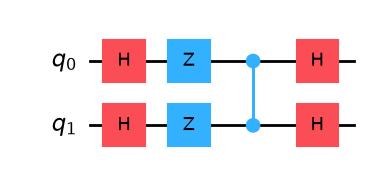

In [4]:
diffuser(2).definition.draw("mpl")

In [5]:
def diffuser(nqubits):
    qc = QuantumCircuit(nqubits)

    # |s> -> |00...0>
    for qubit in range(nqubits):
        qc.h(qubit)

    # |00...0> -> |11...1>
    for qubit in range(nqubits):
        qc.x(qubit)

    # Multi-controlled Z
    qc.h(nqubits - 1)
    qc.mcx(list(range(nqubits - 1)), nqubits - 1)
    qc.h(nqubits - 1)

    # |11...1> -> |00...0>
    for qubit in range(nqubits):
        qc.x(qubit)

    # |00...0> -> |s>
    for qubit in range(nqubits):
        qc.h(qubit)

    U_s = qc.to_gate()
    U_s.name = "$U_s$"

    return U_s

<h1>Gover's Algorithm</h1>

In [6]:

def grover_problem_oracle(n, variant=0, print_solutions=False):
    np.random.seed(variant)

    if n < 3:
        nsolutions = 1
    else:
        nsolutions = np.random.randint(1, np.ceil(2**n/4))

    diagonal_elements = [-1]*nsolutions + [1]*((2**n)-nsolutions)
    np.random.shuffle(diagonal_elements)

    oracle_gate = DiagonalGate(diagonal_elements)
    oracle_gate.name = "Oracle\n=%i, var=%i" % (n, variant)

    if print_solutions:
        print("Solutions:")
        for idx, e in enumerate(diagonal_elements):
            if e < 1:
                print("|%s>" % format(idx, "0%ib" % n))

    return oracle_gate

Solutions:
|101>


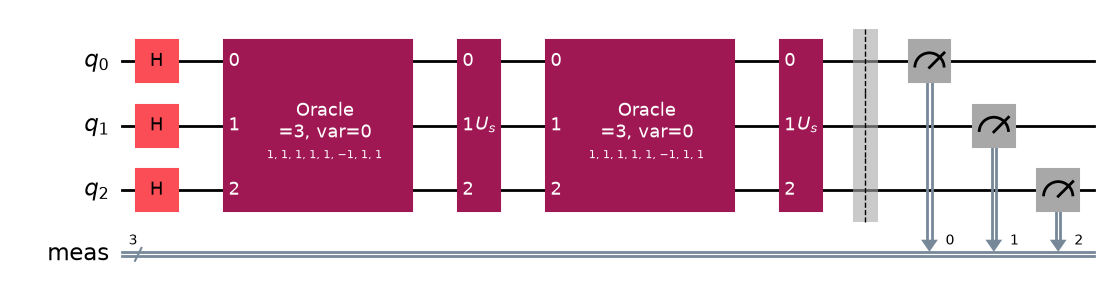

In [7]:
n = 3

oracle = grover_problem_oracle(n,variant=0,print_solutions=True)

grover_circuit = QuantumCircuit(n)

grover_circuit = initialize_s(grover_circuit,[0, 1, 2])

grover_circuit.append(oracle, [0, 1, 2])
grover_circuit.append(diffuser(n), [0, 1, 2])

grover_circuit.append(oracle, [0, 1, 2])
grover_circuit.append(diffuser(n), [0, 1, 2])

grover_circuit.measure_all()

grover_circuit.draw("mpl")

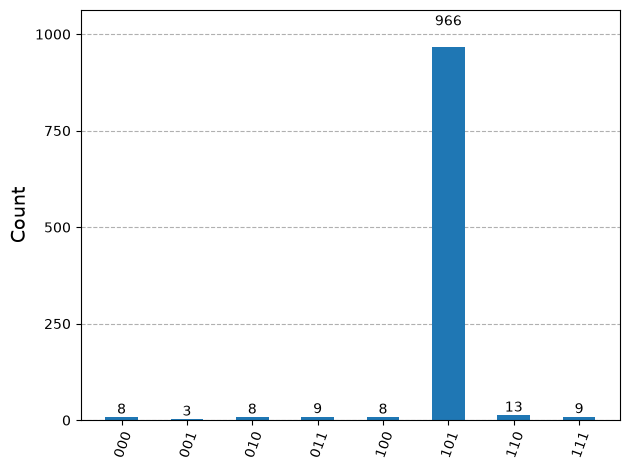

In [8]:
simulator = AerSimulator()

qcc = transpile(grover_circuit, simulator)

job = simulator.run(qcc,shot=1000)

plot_histogram(job.result().get_counts())

<h1>Two Solution Grover</h1>

In [9]:

def grover_problem_oracle(n, variant=0, print_solutions=False):
    np.random.seed(variant)

    '''if n < 3:
        nsolutions = 2
    else:
        nsolutions = np.random.randint(1, np.ceil(2**n/4))'''

    nsolutions = 2

    diagonal_elements = [-1]*nsolutions + [1]*((2**n)-nsolutions)
    np.random.shuffle(diagonal_elements)

    oracle_gate = DiagonalGate(diagonal_elements)
    oracle_gate.name = "Oracle\n=%i, var=%i" % (n, variant)

    if print_solutions:
        print("Solutions:")
        for idx, e in enumerate(diagonal_elements):
            if e < 1:
                print("|%s>" % format(idx, "0%ib" % n))

    return oracle_gate

Solutions:
|010>
|101>


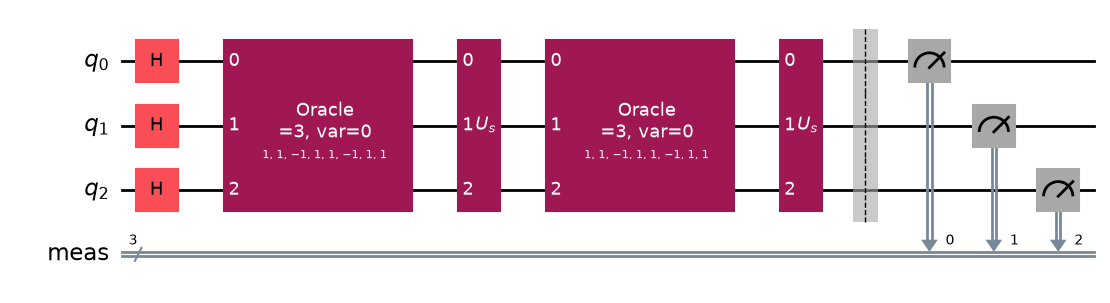

In [10]:
n = 3

oracle = grover_problem_oracle(n,variant=0,print_solutions=True)

grover_circuit = QuantumCircuit(n)

grover_circuit = initialize_s(grover_circuit,[0, 1, 2])

grover_circuit.append(oracle, [0, 1, 2])
grover_circuit.append(diffuser(n), [0, 1, 2])

grover_circuit.append(oracle, [0, 1, 2])
grover_circuit.append(diffuser(n), [0, 1, 2])

grover_circuit.measure_all()

grover_circuit.draw("mpl")

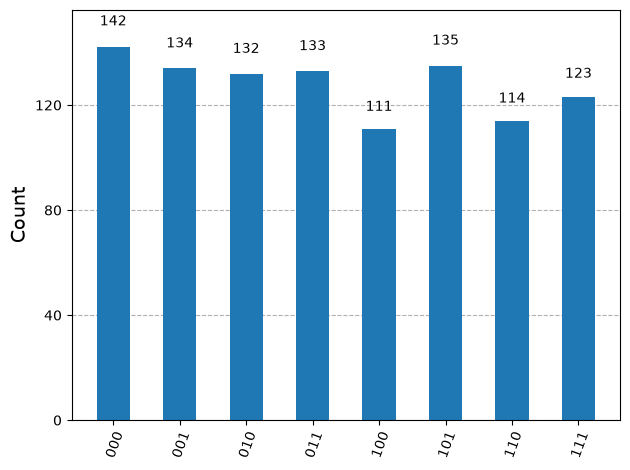

In [11]:
simulator = AerSimulator()

qcc = transpile(grover_circuit, simulator)

job = simulator.run(qcc,shot=1000)

plot_histogram(job.result().get_counts())

Solutions:
|10>
|11>


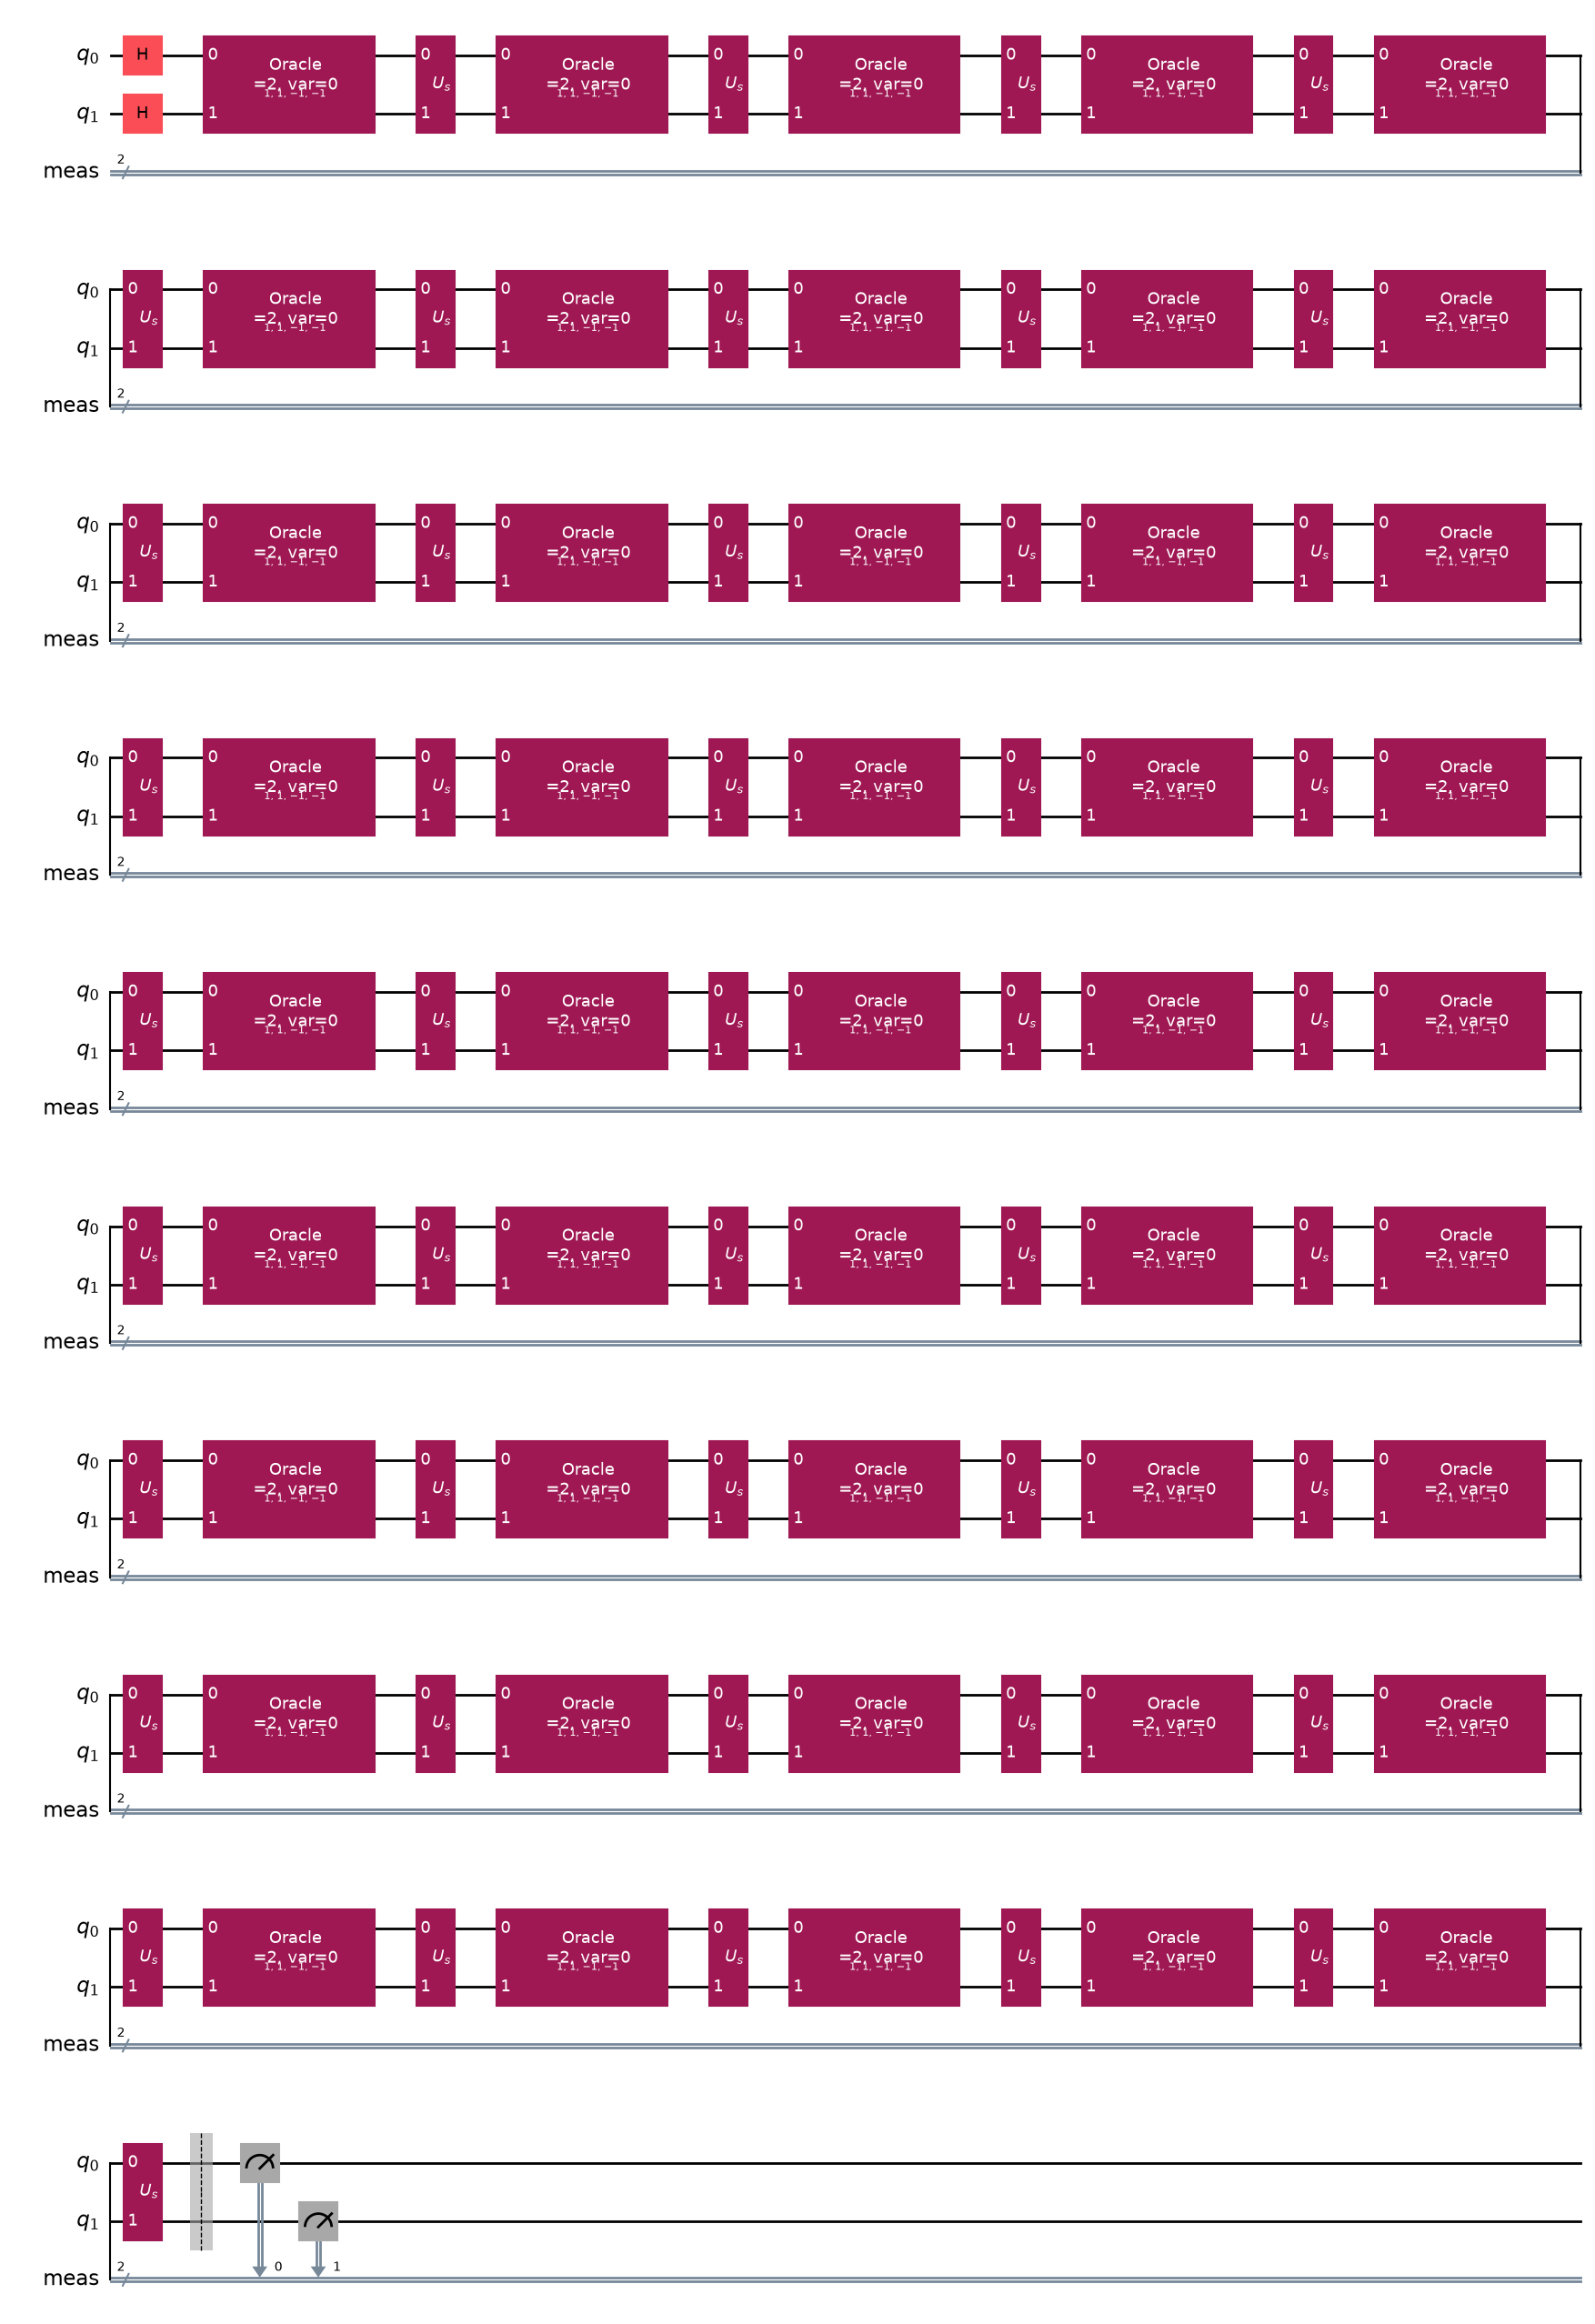

In [95]:
n = 2
iterations = 45

oracle = grover_problem_oracle(n,variant=0,print_solutions=True)

grover_circuit = QuantumCircuit(n)

grover_circuit = initialize_s(grover_circuit,range(n))

for i in range(iterations):
    grover_circuit.append(oracle, range(n))
    grover_circuit.append(diffuser(n), range(n))

grover_circuit.measure_all()

grover_circuit.draw("mpl")

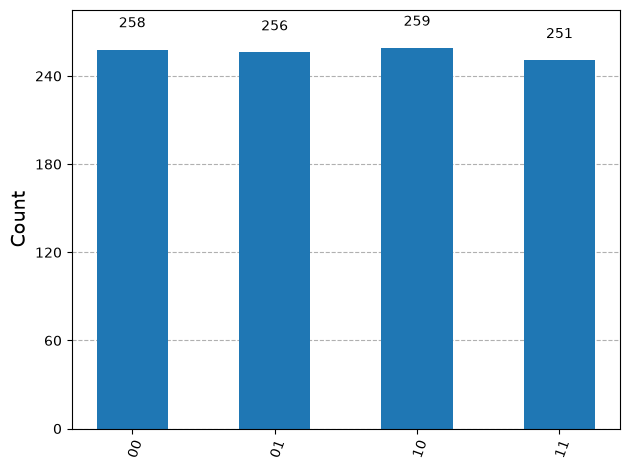

In [96]:
simulator = AerSimulator()

qcc = transpile(grover_circuit, simulator)

job = simulator.run(qcc,shot=1000)

plot_histogram(job.result().get_counts())

3 looks like the right answer
4 makes the noise bigger
